# 2.2 Colonisation time estimate — consensus regression and demo conditions

**Edit `USER_INPUT` in the first code cell, then Run All.** Dependencies: NumPy, pandas, matplotlib and IPython; no scipy, scikit-learn or mycodemo imports are needed. This notebook fits reference guidance, not experimental cultivation outcomes. No `mycodemo` module is imported and nothing is written to that project.

The product has two layers: (1) an unchanged source baseline for the selected species/recipe; (2) a small regression approximating consensus durations, followed by explicit provisional environment rules. Dated photo updates belong in **2.5**; image coverage belongs in **2.4**.

**Demo endpoint:** treat the consensus typical day as 90% visible colonisation, then add **2 days once**. Source min/max durations are retained verbatim; using them as the planning envelope around this reinterpreted endpoint is an explicit demo assumption. This is not a confidence interval or proof of readiness. Species-specific maturation/induction instructions still apply.

No d0xx record enters fitting, calibration or model selection. Those records appear only as labelled contextual points. Source verification is deferred until after the 19 October 2026 demo.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WORK_DIR = Path('/home/sylas/Desktop/mycodemo').resolve()
CONSENSUS_DIR = Path('/home/sylas/Desktop/MycoMaterials/germini').resolve()
BASELINE_PATH = WORK_DIR / 'data/processed/cultivation_baseline.csv'
GUIDE_PATH = WORK_DIR / 'data/processed/cultivation_guide_text.csv'
REVIEW_PATH = CONSENSUS_DIR / 'incubation_temperature_humidity_colonisation_review.md'
COLONISATION_SOURCE_PATH = CONSENSUS_DIR / 'colonisation_consensus.csv'
FRUITING_SOURCE_PATH = CONSENSUS_DIR / 'fruiting_consensus.csv'
CONTEXT_DIR = WORK_DIR / 'data/interim/extracted'
OUTPUT_PARENT = WORK_DIR / 'models/colonisation'
WRITE_OUTPUTS = True
SHOW_CONTEXT = True
RIDGE_ALPHA = 0.10                 # fixed demo regularisation; not tuned on d0xx
POST_90_DAYS = 2.0
TEMP_RATE_LOSS_PER_C = 0.05         # chosen demo assumption, NOT a coefficient in the review
MIN_RELATIVE_RATE = 0.25
MAX_TEMP_DISTANCE_C = 10.0         # no quantitative extrapolation beyond this distance
LOW_RH_THRESHOLD = 60.0
LOW_RH_DELAY_DAYS = (5.0, 10.0)     # report's combined low-RH/dry-substrate scenario, not universal
HARVEST_SPREAD = 0.25              # assumed +/-25% scenario; source table supplies typical only

USER_INPUT = {
    'species': 'Pleurotus ostreatus',
    'substrate': 'straw',
    'temperature_c': 20.0,
    'temperature_basis': 'air',    # 'air', 'substrate_core', or 'unknown'; no fixed core/air conversion
    'humidity_pct': None,          # optional ambient RH, never substrate water content
    'drying_exposed': True,        # low-RH penalty is conditional on drying exposure
    'elapsed_days': 0.0,
    'induction_day': None,         # ACTUAL scheduled/recorded day since inoculation, if known
    'induction_confirmed': False,  # for special maturation/log regimes, confirm readiness explicitly
}

pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 160)

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

source_paths = [BASELINE_PATH, GUIDE_PATH, REVIEW_PATH, COLONISATION_SOURCE_PATH, FRUITING_SOURCE_PATH]
for path in source_paths:
    if not path.is_file():
        raise FileNotFoundError(f'Missing reference file: {path}')
source_hashes = {str(p): digest(p) for p in source_paths}

# Every write goes through this helper and must stay inside the project folder.
def output_path(relative):
    path = (WORK_DIR / relative).resolve()
    if not path.is_relative_to(WORK_DIR):
        raise ValueError('Output must remain inside the project folder.')
    return path

print('References:', BASELINE_PATH, REVIEW_PATH, sep='\n')
print('All outputs remain under:', OUTPUT_PARENT)

References:
/home/sylas/Desktop/mycodemo/data/processed/cultivation_baseline.csv
/home/sylas/Desktop/MycoMaterials/germini/incubation_temperature_humidity_colonisation_review.md
All outputs remain under: /home/sylas/Desktop/mycodemo/models/colonisation


## 1. Read and audit the consensus rows

The 22 structured entries retain exact species and substrate labels. Natural logs form a distinct cultivation regime. The accompanying text is joined by `ref_id`; do not treat the separate germini files as additional independent copies of these same claims.

Eight species are supported. Unsupported species/recipe pairs return an explicit error rather than silently becoming another species or the reference substrate. The source table's confidence labels are preserved as recorded, not independently verified confidence.

In [2]:
baseline = pd.read_csv(BASELINE_PATH)
guide = pd.read_csv(GUIDE_PATH).fillna('')
assert baseline.ref_id.is_unique and guide.ref_id.is_unique
assert set(baseline.ref_id) == set(guide.ref_id)
numeric_columns = [
    'colonisation_days_min', 'colonisation_days_typical', 'colonisation_days_max',
    'incubation_temp_min_C', 'incubation_temp_opt_C', 'incubation_temp_max_C',
    'incubation_RH_pct', 'days_to_pinning_typical', 'days_pinning_to_harvest_typical',
    'days_to_first_harvest_typical',
]
for col in numeric_columns:
    baseline[col] = pd.to_numeric(baseline[col], errors='raise')
assert np.isfinite(baseline[numeric_columns].to_numpy()).all()
assert (baseline.colonisation_days_min > 0).all()
assert (baseline.colonisation_days_min <= baseline.colonisation_days_typical).all()
assert (baseline.colonisation_days_typical <= baseline.colonisation_days_max).all()
assert np.allclose(baseline.days_to_pinning_typical + baseline.days_pinning_to_harvest_typical,
                   baseline.days_to_first_harvest_typical)
assert not baseline.duplicated(['species', 'substrate_code']).any()
baseline['regime'] = np.where(baseline.substrate_code.eq('logs'), 'natural_logs', 'prepared_substrate')
baseline['species_regime'] = baseline.species + ' | ' + baseline.regime
baseline = baseline.merge(guide, on='ref_id', validate='one_to_one')
source_colonisation = pd.read_csv(COLONISATION_SOURCE_PATH)
source_fruiting = pd.read_csv(FRUITING_SOURCE_PATH)
common = list(set(source_colonisation.columns) & set(source_fruiting.columns))
assert source_colonisation.loc[:18, common].fillna('').equals(source_fruiting[common].fillna(''))
print(f'{len(baseline)} unique reference pairs; {baseline.species.nunique()} species. No d0xx training rows.')
print('Source min/max are planning-envelope inputs, not verified 90% crossing bounds.')
display(baseline[['ref_id', 'species', 'substrate_code', 'colonisation_days_min',
                  'colonisation_days_typical', 'colonisation_days_max',
                  'days_to_first_harvest_typical', 'confidence']])

22 unique reference pairs; 8 species. No d0xx training rows.
Source min/max are planning-envelope inputs, not verified 90% crossing bounds.


,ref_id,species,substrate_code,colonisation_days_min,colonisation_days_typical,colonisation_days_max,days_to_first_harvest_typical,confidence
0,cb01,Pleurotus ostreatus,straw,12,14,21,8,High
1,cb02,Pleurotus ostreatus,cotton,10,13,18,7,High
2,cb03,Pleurotus ostreatus,sawdust,14,18,22,9,High
3,cb04,Pleurotus pulmonarius,straw,8,12,16,7,High
4,cb05,Pleurotus pulmonarius,cotton,9,12,15,7,High
5,cb06,Pleurotus pulmonarius,sawdust,12,15,20,8,High
6,cb07,Pleurotus djamor,straw,7,10,14,6,High
7,cb08,Pleurotus djamor,bagasse,8,11,15,7,High
8,cb09,Pleurotus djamor,sawdust,10,14,18,8,Medium
9,cb10,Pleurotus eryngii,sawdust,14,18,25,13,High


## 2. Fit a small consensus regression

Fit five targets from the same 22 rows: log typical 90%-day, lower/upper log ratios, log induction-to-pinning and log pinning-to-harvest. Nonnegative ratio predictions keep the range ordered. These are regularised linear regressions with an unpenalised intercept, using species, substrate and species-by-cultivation-regime indicators. The ridge penalty is fixed, not optimised on experimental data.

Temperature and RH are **not fitted as causal predictors** from a table of recommended conditions. They enter a separate rule layer below. Min/typ/max remain outputs from one reference row, not three independent training examples.

Reference reproduction error measures how closely the model approximates the table. The leave-one-pair-out diagnostic tests missing-reference reconstruction only, not real cultivation accuracy. No automatic claim that the model is better than the reference lookup is made.

In [3]:
FEATURE_FIELDS = ('species', 'substrate_code', 'species_regime')
TARGET_NAMES = ('log_t90', 'lower_log_ratio', 'upper_log_ratio', 'log_pinning', 'log_development')

def feature_matrix(frame, levels):
    return np.column_stack([np.ones(len(frame))] + [
        frame[field].eq(value).to_numpy(float)
        for field in FEATURE_FIELDS for value in levels[field]
    ])

def targets(frame):
    typ = frame.colonisation_days_typical.to_numpy(float)
    return np.column_stack([
        np.log(typ), np.log(typ / frame.colonisation_days_min),
        np.log(frame.colonisation_days_max / typ),
        np.log(frame.days_to_pinning_typical), np.log(frame.days_pinning_to_harvest_typical),
    ])

def fit_consensus(frame, alpha=RIDGE_ALPHA):
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError('ridge alpha must be positive')
    levels = {field: sorted(frame[field].unique().tolist()) for field in FEATURE_FIELDS}
    x = feature_matrix(frame, levels)
    penalty = np.eye(x.shape[1]) * alpha
    penalty[0, 0] = 0.0
    coef = np.linalg.solve(x.T @ x + penalty, x.T @ targets(frame))
    return {'levels': levels, 'coefficients': coef, 'alpha': alpha,
            'training_ref_ids': frame.ref_id.tolist()}

def predict_reference(model, frame):
    pred = feature_matrix(frame, model['levels']) @ np.asarray(model['coefficients'])
    typ = np.exp(pred[:, 0])
    return pd.DataFrame({
        't90_lower': typ * np.exp(-np.maximum(pred[:, 1], 0)),
        't90_typical': typ,
        't90_upper': typ * np.exp(np.maximum(pred[:, 2], 0)),
        'pinning_typical': np.exp(pred[:, 3]),
        'development_typical': np.exp(pred[:, 4]),
    }, index=frame.index)

model = fit_consensus(baseline)
reference_fit = predict_reference(model, baseline)
reproduction = baseline[['ref_id', 'species', 'substrate_code', 'colonisation_days_typical']].join(reference_fit)
reproduction['absolute_reference_error_days'] = abs(reproduction.t90_typical - reproduction.colonisation_days_typical)
reproduction_metrics = {
    'training_reference_rows': len(baseline),
    'reference_reproduction_mae_days': float(reproduction.absolute_reference_error_days.mean()),
    'reference_reproduction_max_error_days': float(reproduction.absolute_reference_error_days.max()),
    'experimental_validation_performed': False,
}
fold_rows = []
for idx, row in baseline.iterrows():
    train = baseline.drop(index=idx)
    missing = [field for field in FEATURE_FIELDS if row[field] not in set(train[field])]
    if missing:
        fold_rows.append({'ref_id': row.ref_id, 'status': 'unrepresented category: ' + ', '.join(missing),
                          'absolute_error_days': np.nan})
        continue
    fold_model = fit_consensus(train)
    pred = float(predict_reference(fold_model, baseline.loc[[idx]]).t90_typical.iloc[0])
    fold_rows.append({'ref_id': row.ref_id, 'status': 'reference reconstruction only',
                      'absolute_error_days': abs(pred - row.colonisation_days_typical)})
reference_cv = pd.DataFrame(fold_rows)
print('Consensus-table approximation, NOT experimental validation:')
print(json.dumps(reproduction_metrics, indent=2))
print('Leave-one-reference-pair-out: comparable folds', int(reference_cv.absolute_error_days.notna().sum()),
      'of', len(reference_cv), '; unavailable categories remain explicitly unscored.')
display(reproduction.round(2))

Consensus-table approximation, NOT experimental validation:
{
  "training_reference_rows": 22,
  "reference_reproduction_mae_days": 1.7152124272171292,
  "reference_reproduction_max_error_days": 18.66573039405793,
  "experimental_validation_performed": false
}
Leave-one-reference-pair-out: comparable folds 16 of 22 ; unavailable categories remain explicitly unscored.


,ref_id,species,substrate_code,colonisation_days_typical,t90_lower,t90_typical,t90_upper,pinning_typical,development_typical,absolute_reference_error_days
0,cb01,Pleurotus ostreatus,straw,14,11.20,14.15,20.02,3.81,3.90,0.15
1,cb02,Pleurotus ostreatus,cotton,13,11.50,14.31,19.14,3.66,4.06,1.31
2,cb03,Pleurotus ostreatus,sawdust,18,13.17,16.41,22.03,4.38,4.14,1.59
3,cb04,Pleurotus pulmonarius,straw,12,9.00,12.34,16.72,3.22,3.90,0.34
4,cb05,Pleurotus pulmonarius,cotton,12,9.24,12.48,15.98,3.10,4.06,0.48
5,cb06,Pleurotus pulmonarius,sawdust,15,10.59,14.32,18.40,3.70,4.14,0.68
6,cb07,Pleurotus djamor,straw,10,7.76,11.03,15.24,3.26,3.42,1.03
7,cb08,Pleurotus djamor,bagasse,11,8.13,11.20,15.22,3.03,3.97,0.20
8,cb09,Pleurotus djamor,sawdust,14,9.12,12.80,16.77,3.74,3.63,1.20
9,cb10,Pleurotus eryngii,sawdust,18,14.70,19.08,25.63,7.37,6.16,1.08


## 3. Environmental rules — editable demo assumptions

Source: `germini/incubation_temperature_humidity_colonisation_review.md`, sections 2, 3 and 5. Bibliographic verification is deferred. The report provides recommended temperature bands, selected PDA extension rates, and a **combined low-RH/dry-substrate** delay claim. It supplies no fitted duration-response equation. PDA rates are not substrate colonisation training labels.

**Temperature:** use the report's air/core optimum bands for the five represented species it covers. For others, use the selected reference entry's optimum only, labelled as a basis assumption; air temperature then cannot be adjusted without an air recommendation. Relative rate is 1 within the optimum band, falling by a chosen **5 percentage points per degree** outside it, down to 0.25. Duration is divided by that relative rate. This numerical slope is a configurable demo assumption, not a published coefficient. Decline numeric extrapolation beyond 10 degrees from the band, or at/above 35 C. No fixed air-to-core offset is applied.

**Humidity:** below 60% ambient RH, only for a drying-exposed scenario, add a provisional **5–10-day** delay (7.5-day centre). RH is not measured substrate moisture. Above that threshold or for sealed/protected substrate, do not invent a humidity slope. Report deviations from recommendations separately. Missing RH stays missing.

**Harvest:** regress typical stage durations. The table has no harvest range, so the displayed +/-25% envelope around their sum is an explicitly assumed planning scenario, not a sourced range or confidence interval. Incubation conditions are not reused as fruiting conditions. Fruiting updates require a separate stage model in later work.

In [4]:
# Values transcribed from the supplied review summary, not independently verified.
REVIEW_OPTIMA = {
    'Pleurotus ostreatus': {'substrate_core': (23., 25.), 'air': (18., 20.)},
    'Pleurotus pulmonarius': {'substrate_core': (24., 28.), 'air': (20., 24.)},
    'Pleurotus eryngii': {'substrate_core': (24., 24.), 'air': (18., 22.)},
    'Lentinula edodes': {'substrate_core': (23., 25.), 'air': (18., 22.)},
    'Ganoderma lucidum': {'substrate_core': (27., 30.), 'air': (24., 26.)},
}

def finite_number(value, name, lower=None, upper=None):
    value = float(value)
    if not np.isfinite(value) or (lower is not None and value < lower) or (upper is not None and value > upper):
        raise ValueError(f'Invalid {name}: {value}')
    return value

def environment_rules(row, temperature_c, temperature_basis, humidity_pct, drying_exposed):
    notes, factor = [], 1.0
    available = True
    if temperature_basis not in ('air', 'substrate_core', 'unknown'):
        raise ValueError('temperature_basis must be air, substrate_core or unknown')
    optima = REVIEW_OPTIMA.get(row.species, {})
    band = optima.get(temperature_basis)
    band_source = 'review optimum band'
    if band is None and temperature_basis == 'substrate_core':
        band = (float(row.incubation_temp_opt_C),) * 2
        band_source = 'reference optimum treated as core temperature: demo basis assumption'
    if temperature_c is None:
        notes.append('Temperature omitted: reference scenario, no adjustment.')
    else:
        temp = finite_number(temperature_c, 'temperature', -20, 60)
        if band is None:
            available = False
            notes.append('No comparable temperature basis/recommendation; numeric adjusted forecast unavailable.')
        else:
            distance = max(band[0] - temp, 0., temp - band[1])
            if distance > MAX_TEMP_DISTANCE_C or temp >= 35.:
                available = False
                notes.append('Temperature outside the provisional quantitative domain; numeric adjusted forecast unavailable.')
            else:
                rate = max(MIN_RELATIVE_RATE, 1. - TEMP_RATE_LOSS_PER_C * distance)
                factor = 1. / rate
            notes.append(f'{temperature_basis} optimum {band}; {band_source}; no air/core conversion.')
    delay = (0., 0., 0.)
    if humidity_pct is None:
        notes.append('Ambient RH not supplied; no humidity adjustment.')
    else:
        rh = finite_number(humidity_pct, 'humidity', 0, 100)
        if rh < LOW_RH_THRESHOLD and drying_exposed:
            low, high = LOW_RH_DELAY_DAYS
            delay = (low, (low + high) / 2, high)
            notes.append('Low-RH AND drying-exposure scenario: assumed 5-10 day delay; not measured substrate dryness.')
        elif rh < LOW_RH_THRESHOLD:
            notes.append('Low room RH, but drying exposure disabled: no duration penalty assigned.')
        if rh < float(row.incubation_RH_pct):
            notes.append('RH below this reference recommendation; the table alone gives no calibrated RH-duration slope.')
        if rh > 95:
            notes.append('High ambient RH does not establish excess substrate moisture; no automatic duration penalty.')
    return {'available': available, 'temperature_duration_factor': factor,
            'humidity_delay_days': delay, 'optimum_band': band, 'notes': notes}

SPECIES_ALIASES = {
    'pearl oyster': 'Pleurotus ostreatus', 'blue oyster': 'Pleurotus ostreatus',
    'phoenix oyster': 'Pleurotus pulmonarius', 'pink oyster': 'Pleurotus djamor',
    'king oyster': 'Pleurotus eryngii', 'shiitake': 'Lentinula edodes',
    "lion's mane": 'Hericium erinaceus', 'reishi': 'Ganoderma lucidum',
    'enoki': 'Flammulina velutipes',
}
SUBSTRATE_ALIASES = {'cotton waste': 'cotton', 'natural logs': 'logs', "master's mix": 'masters_mix'}

def selected_reference(species, substrate):
    species = SPECIES_ALIASES.get(str(species).strip().lower(), str(species).strip())
    exact = {s.lower(): s for s in baseline.species.unique()}
    species = exact.get(species.lower(), species)
    substrate = SUBSTRATE_ALIASES.get(str(substrate).strip().lower(), str(substrate).strip().lower())
    selected = baseline[(baseline.species == species) & (baseline.substrate_code == substrate)]
    if len(selected) != 1:
        choices = baseline.loc[baseline.species.eq(species), 'substrate_code'].tolist()
        raise ValueError(f'Unsupported species/substrate pair: {species} / {substrate}. Available substrates: {choices}')
    return selected

def estimate_days(species, substrate, temperature_c=None, humidity_pct=None,
                  temperature_basis='unknown', drying_exposed=True, elapsed_days=0.,
                  induction_day=None, induction_confirmed=False):
    elapsed = finite_number(elapsed_days, 'elapsed days', 0)
    frame = selected_reference(species, substrate)
    row = frame.iloc[0]
    fit = predict_reference(model, frame).iloc[0]
    rules = environment_rules(row, temperature_c, temperature_basis, humidity_pct, drying_exposed)
    source_range = [float(row.colonisation_days_min), float(row.colonisation_days_typical), float(row.colonisation_days_max)]
    reference_t90 = [float(fit.t90_lower), float(fit.t90_typical), float(fit.t90_upper)]
    adjusted = None
    if rules['available']:
        adjusted = [v * rules['temperature_duration_factor'] + d
                    for v, d in zip(reference_t90, rules['humidity_delay_days'])]
    marker = None if adjusted is None else [v + POST_90_DAYS for v in adjusted]
    special = row.species == 'Lentinula edodes' or row.regime == 'natural_logs'
    notes = list(rules['notes'])
    if special:
        notes.append('Maturation/log regime: 90% + 2 days is a planning marker, not verified induction readiness. Review guide actions.')
    harvest_typ = float(fit.pinning_typical + fit.development_typical)
    harvest_stage = [harvest_typ * (1 - HARVEST_SPREAD), harvest_typ, harvest_typ * (1 + HARVEST_SPREAD)]
    harvest = None
    if induction_day is not None:
        actual_induction = finite_number(induction_day, 'induction day', 0)
        harvest = [actual_induction + v for v in harvest_stage]
        notes.append('Harvest clock anchored to entered induction day; incubation adjustment does not alter fruiting duration.')
    elif marker is not None and (not special or induction_confirmed):
        harvest = [a + b for a, b in zip(marker, harvest_stage)]
        notes.append('Harvest assumes induction starts at the planning marker and suitable fruiting conditions follow.')
    else:
        notes.append('Harvest date unavailable until an induction day or appropriate maturation confirmation is provided.')
    remaining = lambda days: None if days is None else [max(0., v - elapsed) for v in days]
    return {
        'species': row.species, 'substrate': row.substrate_code, 'ref_id': row.ref_id,
        'source_colonisation_days_min_typ_max': source_range,
        'source_first_harvest_stage_typical_days': float(row.days_to_first_harvest_typical),
        'consensus_regression_t90_min_typ_max': reference_t90,
        'adjusted_t90_min_typ_max': adjusted,
        'planning_90_plus_2_day_min_typ_max': marker,
        'planning_90_plus_2_days_remaining': remaining(marker),
        'harvest_day_min_typ_max': harvest,
        'harvest_days_remaining': remaining(harvest),
        'harvest_stage_min_typ_max': harvest_stage,
        'harvest_range_basis': 'assumed +/-25% stage envelope; not sourced bounds',
        'elapsed_days': elapsed, 'conditions': {'temperature_c': temperature_c, 'temperature_basis': temperature_basis,
                                               'humidity_pct': humidity_pct, 'drying_exposed': drying_exposed},
        'environment_rules': rules, 'needs_maturation_review': special,
        'induction_actions': row.induction_actions, 'colonisation_cautions': row.colonisation_cautions,
        'source_reference': row.source_reference, 'source_confidence_as_recorded': row.confidence,
        'endpoint_basis': 'typical consensus duration treated as 90%; +2 days once; range envelope assumed',
        'model_basis': 'consensus regression plus provisional environmental rules; not experimentally validated',
        'notes': notes,
    }

## 4. Your batch — edit USER_INPUT above

The output separates the original source baseline, regression at reference conditions and adjusted planning estimates. All displayed ranges are planning envelopes. A room-temperature input uses an explicit air recommendation where available; it never silently becomes a substrate-core measurement.

`elapsed_days` subtracts time already spent; changing conditions here recomputes a **constant-condition scenario**, not a reconstruction of past exposure. Dated condition-history accumulation and photo assimilation remain work for 2.5. An entered induction day starts a separate harvest clock. Negative remaining durations are clipped to zero, not treated as evidence that a batch is biologically ready.

In [5]:
result = estimate_days(**USER_INPUT)
rows = [
    ('Source colonisation duration (original definition)', result['source_colonisation_days_min_typ_max']),
    ('Regression 90% day, reference conditions', result['consensus_regression_t90_min_typ_max']),
    ('Adjusted 90% day, demo rules', result['adjusted_t90_min_typ_max']),
    ('90% + 2 days: planning day since inoculation', result['planning_90_plus_2_day_min_typ_max']),
    ('90% + 2 days: days remaining', result['planning_90_plus_2_days_remaining']),
    ('First harvest: days remaining, conditional scenario', result['harvest_days_remaining']),
]
summary = pd.DataFrame([{'estimate': name, 'lower': None if values is None else values[0],
                         'typical': None if values is None else values[1],
                         'upper': None if values is None else values[2]} for name, values in rows])
print(result['species'], '/', result['substrate'])
display(summary.round(1))
print('Harvest envelope:', result['harvest_range_basis'])
for note in result['notes']:
    print('- ' + note)
print('Induction actions:', result['induction_actions'])
print('Reference:', result['source_reference'])

# Documented numeric interface for 2.5. No photos are fabricated or assimilated here.
forecast_payload = {
    'schema_version': 1, 'producer': '2.2.colonisation_time_estimate',
    'species': result['species'], 'substrate': result['substrate'],
    'target': 'visible_coverage_90_percent_plus_2_days', 'post_90_days': POST_90_DAYS,
    'elapsed_days': result['elapsed_days'],
    'reference_t90_min_typ_max': result['consensus_regression_t90_min_typ_max'],
    'adjusted_t90_min_typ_max': result['adjusted_t90_min_typ_max'],
    'harvest_stage_min_typ_max': result['harvest_stage_min_typ_max'],
    'needs_maturation_review': result['needs_maturation_review'],
    'induction_day': USER_INPUT['induction_day'], 'conditions': result['conditions'],
    'coverage_observations': [], 'condition_history': [],
    'assumptions': result['notes'], 'reference_id': result['ref_id'],
}

Pleurotus ostreatus / straw


,estimate,lower,typical,upper
0,Source colonisation duration (original definit...,12.0,14.0,21.0
1,"Regression 90% day, reference conditions",11.2,14.1,20.0
2,"Adjusted 90% day, demo rules",11.2,14.1,20.0
3,90% + 2 days: planning day since inoculation,13.2,16.1,22.0
4,90% + 2 days: days remaining,13.2,16.1,22.0
5,"First harvest: days remaining, conditional sce...",19.0,23.9,31.7


Harvest envelope: assumed +/-25% stage envelope; not sourced bounds
- air optimum (18.0, 20.0); review optimum band; no air/core conversion.
- Ambient RH not supplied; no humidity adjustment.
- Harvest assumes induction starts at the planning marker and suitable fruiting conditions follow.
Induction actions: Open or cut slits in cultivation bag, lower ambient temperature to 10-16 C, increase fresh air exchange, and introduce indirect light to initiate pinning.
Reference: Penn State Extension (Royse, 2003); Ten Speed Press (Stamets, 2000), pp. 308-315; ICAR-DMR Solan (2020), p. 24


## 5. Inspect reference fit and condition sensitivity

The first plot compares reference durations with their regression approximation. The second demonstrates the chosen temperature rule for this species/basis; it is not an observed temperature experiment. The third shows the source band and the conditional planning forecasts. Lower/upper source durations in the first plot retain their original endpoint definitions.

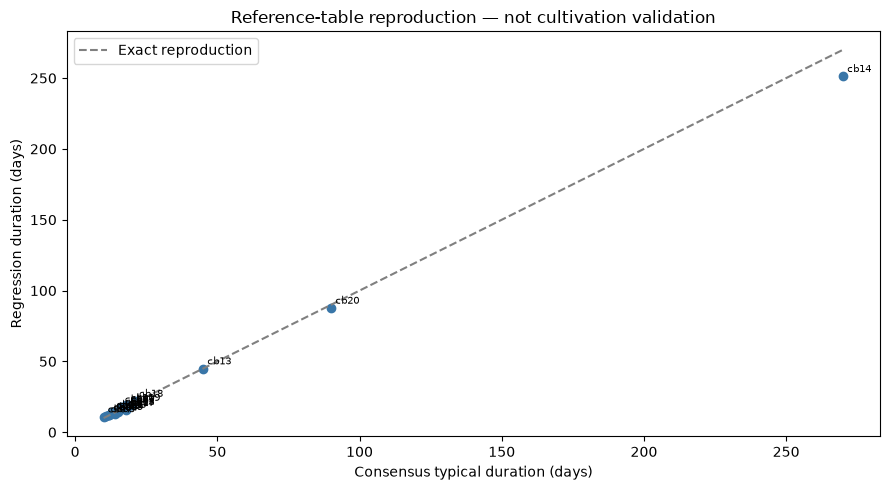

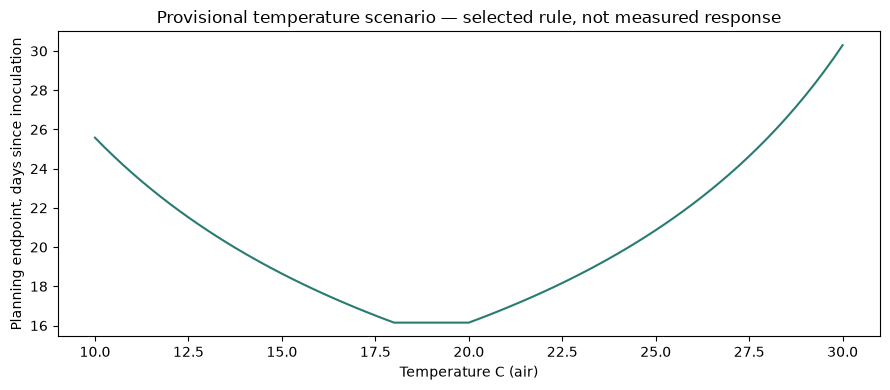

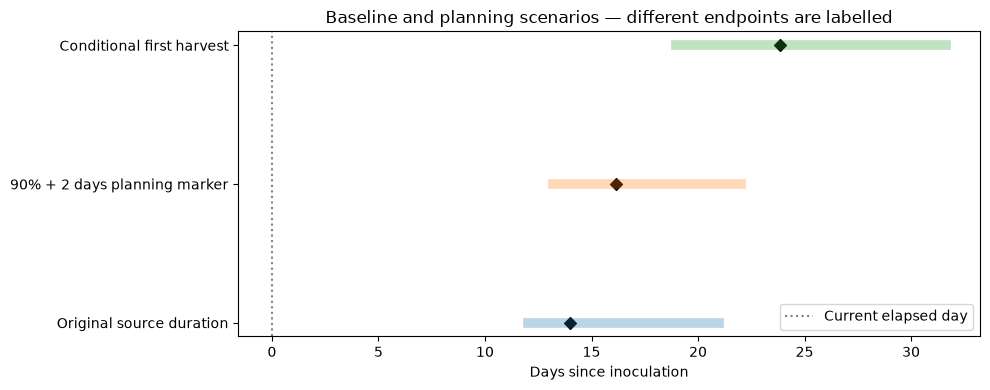

In [6]:
figures = {}
fig, ax = plt.subplots(figsize=(9, 5))
x = baseline.colonisation_days_typical.to_numpy(float)
y = reference_fit.t90_typical.to_numpy(float)
ax.scatter(x, y, color='#3976a8')
ax.plot([x.min(), x.max()], [x.min(), x.max()], '--', color='grey', label='Exact reproduction')
for i, row in baseline.iterrows():
    ax.annotate(row.ref_id, (x[i], y[i]), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set(xlabel='Consensus typical duration (days)', ylabel='Regression duration (days)',
       title='Reference-table reproduction — not cultivation validation')
ax.legend(); fig.tight_layout(); figures['reference_reproduction'] = fig
plt.show()

selected = selected_reference(USER_INPUT['species'], USER_INPUT['substrate']).iloc[0]
fig, ax = plt.subplots(figsize=(9, 4))
temps = np.linspace(10, 36, 105)
values = []
for temp in temps:
    r = estimate_days(**{**USER_INPUT, 'temperature_c': float(temp), 'humidity_pct': None})
    v = r['planning_90_plus_2_day_min_typ_max']
    values.append(np.nan if v is None else v[1])
ax.plot(temps, values, color='#287c6f')
ax.set(xlabel=f"Temperature C ({USER_INPUT['temperature_basis']})", ylabel='Planning endpoint, days since inoculation',
       title='Provisional temperature scenario — selected rule, not measured response')
fig.tight_layout(); figures['temperature_scenario'] = fig
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
plot_rows = [(name, vals) for name, vals in [
    ('Original source duration', result['source_colonisation_days_min_typ_max']),
    ('90% + 2 days planning marker', result['planning_90_plus_2_day_min_typ_max']),
    ('Conditional first harvest', result['harvest_day_min_typ_max'])] if vals is not None]
for i, (name, vals) in enumerate(plot_rows):
    ax.plot([vals[0], vals[2]], [i, i], linewidth=7, alpha=.3)
    ax.scatter(vals[1], i, marker='D', color='black')
ax.axvline(result['elapsed_days'], linestyle=':', color='grey', label='Current elapsed day')
ax.set_yticks(range(len(plot_rows)), [r[0] for r in plot_rows])
ax.set(xlabel='Days since inoculation', title='Baseline and planning scenarios — different endpoints are labelled')
ax.legend(); fig.tight_layout(); figures['batch_planning'] = fig
plt.show()

## 6. d0xx context only — never fitted or scored

Plot the available P. ostreatus study recipe endpoints alongside this species' consensus substrate bands and regression estimates (black crosses). These are heterogeneous recipes and completion definitions, not matched validation cases. d025/d026 provide recipe completion means, not full trajectories. d002 uses ordinal score 5 (95–100% class); five unfinished recipes remain as right-pointing markers at last observation. Numeric spawn denominators are unverified.

The contextual plot does not use the experimental records to choose model settings, calculate accuracy or learn environmental effects. Original species, substrate, source and endpoint labels are retained in the exported context table.

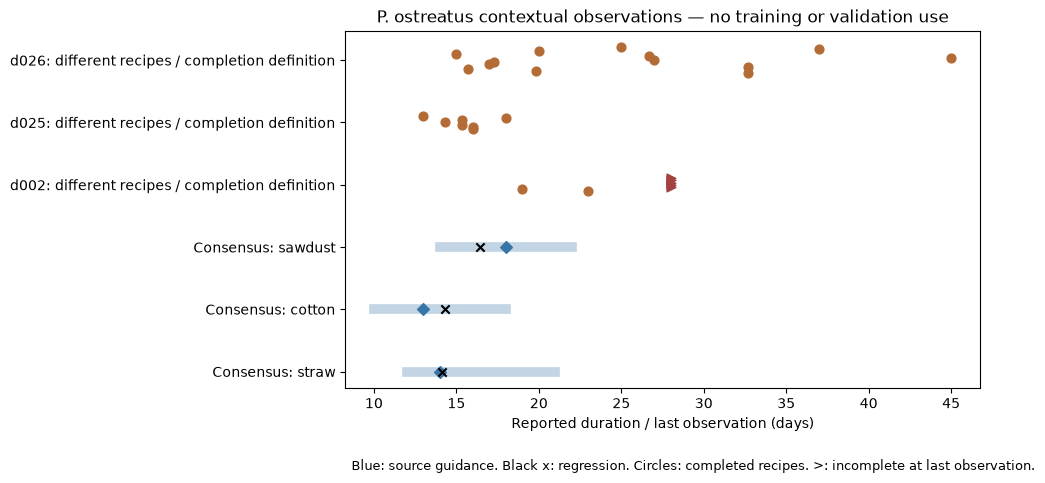

,dataset_id,sample_id,species,substrate,temperature_c,humidity_pct,spawn_pct_as_recorded,endpoint_day,last_observed_day,completed,endpoint_definition,role
0,d002,d002-G-R1,Pleurotus ostreatus,straw + soy hull,24.0,NaN,4.8,23.00,28.00,True,score 5 (95-100%),context only; excluded from regression and met...
1,d002,d002-G-R2,Pleurotus ostreatus,cotton + soy hull,24.0,NaN,4.8,19.00,28.00,True,score 5 (95-100%),context only; excluded from regression and met...
2,d002,d002-G-R3,Pleurotus ostreatus,straw + inedible plant biomass,24.0,NaN,4.8,NaN,28.00,False,score 5 (95-100%),context only; excluded from regression and met...
3,d002,d002-G-R4,Pleurotus ostreatus,cotton + inedible plant biomass,24.0,NaN,4.8,NaN,28.00,False,score 5 (95-100%),context only; excluded from regression and met...
4,d002,d002-G-R5,Pleurotus ostreatus,cotton + inedible plant biomass,24.0,NaN,4.8,NaN,28.00,False,score 5 (95-100%),context only; excluded from regression and met...
5,d002,d002-G-R6,Pleurotus ostreatus,cotton,24.0,NaN,4.8,NaN,28.00,False,score 5 (95-100%),context only; excluded from regression and met...
6,d002,d002-G-R7,Pleurotus ostreatus,cotton + inedible plant biomass + food packagi...,24.0,NaN,4.8,NaN,28.00,False,score 5 (95-100%),context only; excluded from regression and met...
7,d025,d025-G-T1,Pleurotus ostreatus,tef straw,25.0,85.0,6.5,16.00,16.00,True,reported 100% completion mean,context only; excluded from regression and met...
8,d025,d025-G-T2,Pleurotus ostreatus,barley straw,25.0,85.0,6.5,16.00,16.00,True,reported 100% completion mean,context only; excluded from regression and met...
9,d025,d025-G-T3,Pleurotus ostreatus,wheat straw,25.0,85.0,6.5,15.33,15.33,True,reported 100% completion mean,context only; excluded from regression and met...


In [7]:
context = pd.DataFrame()
if SHOW_CONTEXT:
    paths = {name: CONTEXT_DIR / f'{name}.csv' for name in ['measurement', 'sample', 'fermentation', 'substrate']}
    if all(p.is_file() for p in paths.values()):
        source_hashes.update({str(p): digest(p) for p in paths.values()})
        m, s, f, su = [pd.read_csv(paths[name]) for name in paths]
        joined = (m.merge(s, on=['dataset_id', 'sample_id'], validate='many_to_one')
                  .merge(f, on='fermentation_id', validate='many_to_one')
                  .merge(su, on='substrate_id', validate='many_to_one'))
        records = []
        selected_rows = joined[(joined.measurement_type == 'mean') & joined.dataset_id.isin(['d002', 'd025', 'd026'])]
        for (dataset, sid), group in selected_rows.groupby(['dataset_id', 'sample_id']):
            group = group.sort_values('day_of_growth')
            full = group[(group.surface_colonised_pct >= 100) | (group.colonisation_score >= 5)]
            row = group.iloc[0]
            complete = not full.empty
            records.append({
                'dataset_id': dataset, 'sample_id': sid, 'species': f'{row.genus} {row.species}',
                'substrate': row.plant_name, 'temperature_c': row.incubation_temp_c,
                'humidity_pct': row.rh_pct, 'spawn_pct_as_recorded': row.spawn_pct_wt,
                'endpoint_day': float(full.day_of_growth.iloc[0]) if complete else None,
                'last_observed_day': float(group.day_of_growth.max()), 'completed': complete,
                'endpoint_definition': 'score 5 (95-100%)' if dataset == 'd002' else 'reported 100% completion mean',
                'role': 'context only; excluded from regression and metrics',
            })
        context = pd.DataFrame(records)
        fig, ax = plt.subplots(figsize=(10, 5))
        ref = baseline[baseline.species.eq('Pleurotus ostreatus')]
        positions, labels = [], []
        for y, (_, row) in enumerate(ref.iterrows()):
            ax.plot([row.colonisation_days_min, row.colonisation_days_max], [y, y], lw=7, alpha=.3, color='#3976a8')
            ax.scatter(row.colonisation_days_typical, y, marker='D', color='#3976a8')
            ax.scatter(reference_fit.loc[row.name, 't90_typical'], y, marker='x', color='black', zorder=4)
            positions.append(y); labels.append('Consensus: ' + row.substrate_code)
        for y, dataset in enumerate(['d002', 'd025', 'd026'], start=len(ref)):
            part = context[context.dataset_id.eq(dataset)].reset_index(drop=True)
            for j, row in part.iterrows():
                day = row.endpoint_day if row.completed else row.last_observed_day
                jitter = (j - (len(part) - 1) / 2) * .035
                ax.scatter(day, y + jitter, marker='o' if row.completed else '>',
                           color='#b36c35' if row.completed else '#a44141', s=40)
            positions.append(y); labels.append(dataset + ': different recipes / completion definition')
        ax.set_yticks(positions, labels)
        ax.set(xlabel='Reported duration / last observation (days)',
               title='P. ostreatus contextual observations — no training or validation use')
        ax.text(.01, -.23, 'Blue: source guidance. Black x: regression. Circles: completed recipes. >: incomplete at last observation.',
                transform=ax.transAxes, fontsize=9)
        fig.tight_layout(); figures['context_only'] = fig
        plt.show()
        display(context)
    else:
        print('Optional contextual files unavailable; consensus model is unaffected.')

## 7. Check behaviour, then save a reloadable output bundle

Checks cover endpoint arithmetic, missing/invalid conditions, unsupported categories, temperature basis, RH exposure, maturation and independent harvest clocks. These are software checks, not biological validation. The original reference hashes must remain unchanged.

Each run saves its prepared reference table, coefficients, rules, settings, prediction/payload, approximation diagnostics, contextual points, plots and source hashes inside `models/colonisation/`. Reruns create new timestamped folders.

In [8]:
checks = []
def checked(name, condition):
    assert bool(condition), name
    checks.append(name)

base_args = dict(species='Pleurotus ostreatus', substrate='straw', temperature_c=24., temperature_basis='substrate_core')
r0 = estimate_days(**base_args)
checked('post-90 allowance is added once', np.allclose(np.array(r0['planning_90_plus_2_day_min_typ_max']) - r0['adjusted_t90_min_typ_max'], POST_90_DAYS))
checked('range stays ordered', all(np.diff(r0['planning_90_plus_2_day_min_typ_max']) >= 0))
checked('reference temperature has unit factor', r0['environment_rules']['temperature_duration_factor'] == 1.)
r_cool = estimate_days(**{**base_args, 'temperature_c': 20.})
checked('cooler scenario takes longer', r_cool['planning_90_plus_2_day_min_typ_max'][1] > r0['planning_90_plus_2_day_min_typ_max'][1])
r_dry = estimate_days(**base_args, humidity_pct=50.)
checked('dry-exposed scenario adds 5-10 day envelope', np.allclose(np.array(r_dry['adjusted_t90_min_typ_max']) - r0['adjusted_t90_min_typ_max'], [5, 7.5, 10]))
r_sealed = estimate_days(**base_args, humidity_pct=50., drying_exposed=False)
checked('low RH is not automatically substrate dryness', np.allclose(r_sealed['adjusted_t90_min_typ_max'], r0['adjusted_t90_min_typ_max']))
r_hot = estimate_days(**{**base_args, 'temperature_c': 35.})
checked('outside domain returns no numeric adjusted forecast', r_hot['adjusted_t90_min_typ_max'] is None)
r_unknown = estimate_days(**{**base_args, 'temperature_basis': 'unknown'})
checked('unknown temperature basis is not silently converted', r_unknown['adjusted_t90_min_typ_max'] is None)
r_elapsed = estimate_days(**base_args, elapsed_days=1000)
checked('remaining days are nonnegative', r_elapsed['planning_90_plus_2_days_remaining'] == [0., 0., 0.])
r_ind = estimate_days(**{**base_args, 'temperature_c': 35.}, induction_day=12.)
checked('recorded induction uses independent harvest clock', r_ind['harvest_day_min_typ_max'] is not None)
r_shiitake = estimate_days('Lentinula edodes', 'sawdust')
checked('maturation requires induction confirmation', r_shiitake['needs_maturation_review'] and r_shiitake['harvest_day_min_typ_max'] is None)
for kwargs in [dict(humidity_pct=101), dict(elapsed_days=-1)]:
    try:
        estimate_days(**base_args, **kwargs)
    except ValueError:
        checks.append('invalid input rejected: ' + next(iter(kwargs)))
    else:
        raise AssertionError('invalid input was accepted')
try:
    estimate_days('Pleurotus ostreatus', 'logs')
except ValueError:
    checks.append('unsupported pair rejected rather than extrapolated')
else:
    raise AssertionError('unsupported pair was accepted')
checked('no contextual rows in training manifest', set(model['training_ref_ids']) == set(baseline.ref_id) and all(r.startswith('cb') for r in model['training_ref_ids']))
checked('source file contents unchanged', all(digest(path) == sha for path, sha in source_hashes.items()))
print(f'{len(checks)} software checks passed. No experimental validation claimed.')

16 software checks passed. No experimental validation claimed.


In [9]:
run_dir = None
if WRITE_OUTPUTS:
    run_id = 'consensus_demo_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir = output_path(Path('models/colonisation') / run_id)
    run_dir.mkdir(parents=True, exist_ok=False)
    baseline.to_csv(run_dir / 'prepared_consensus.csv', index=False)
    reproduction.to_csv(run_dir / 'reference_reproduction.csv', index=False)
    reference_cv.to_csv(run_dir / 'reference_reconstruction_cv.csv', index=False)
    summary.to_csv(run_dir / 'batch_summary.csv', index=False)
    if not context.empty:
        context.to_csv(run_dir / 'context_only.csv', index=False)
    settings = {
        'ridge_alpha': RIDGE_ALPHA, 'post_90_days': POST_90_DAYS,
        'temperature_rate_loss_per_degree_assumed': TEMP_RATE_LOSS_PER_C,
        'temperature_min_relative_rate_assumed': MIN_RELATIVE_RATE,
        'temperature_max_distance_degrees_assumed': MAX_TEMP_DISTANCE_C,
        'low_RH_threshold_assumed': LOW_RH_THRESHOLD,
        'low_RH_drying_exposure_delay_scenario': LOW_RH_DELAY_DAYS,
        'harvest_relative_spread_assumed': HARVEST_SPREAD,
        'review_temperature_optima': REVIEW_OPTIMA,
        'training_basis': '22 consensus rows only; no experimental outcomes',
        'python_version': platform.python_version(), 'numpy_version': np.__version__,
        'pandas_version': pd.__version__, 'user_input': USER_INPUT,
    }
    serial_model = {**model, 'coefficients': model['coefficients'].tolist(),
                    'feature_fields': FEATURE_FIELDS, 'target_names': TARGET_NAMES}
    for name, value in [('model.json', serial_model), ('settings.json', settings),
                        ('prediction.json', result), ('forecast_payload.json', forecast_payload),
                        ('reference_metrics.json', reproduction_metrics), ('source_hashes.json', source_hashes),
                        ('software_checks.json', checks)]:
        (run_dir / name).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n')
    for name, fig in figures.items():
        fig.savefig(run_dir / f'{name}.png', dpi=150, bbox_inches='tight')
    (run_dir / 'notes.md').write_text(
        '# Consensus demo run\n\n'
        'Fits reference guidance, not real-world outcome data. Environmental coefficients and harvest range spread are provisional demo assumptions. '
        'Typical reference day is treated as 90% coverage; add two days once. Source range endpoints remain original in prepared_consensus.csv. '
        'The planning envelopes are not confidence intervals. d0xx records are contextual only. '
        'Photo and condition-history assimilation are not implemented in 2.2. '
        'Temperature/RH adjustment affects colonisation, not the separate fruiting-duration scenario.\n')
    checked('reference contents unchanged after output export', all(digest(path) == sha for path, sha in source_hashes.items()))
    (run_dir / 'software_checks.json').write_text(json.dumps(checks, indent=2) + '\n')
    print('Saved bundle:', run_dir)
else:
    print('WRITE_OUTPUTS=False: calculated in memory; no run bundle saved.')

Saved bundle: /home/sylas/Desktop/mycodemo/models/colonisation/consensus_demo_20261019T094807_319906Z


## What comes next

Use `forecast_payload.json` as an explicit starting estimate for **2.5**. That notebook must assimilate actual dated observations from **2.4**, rather than treat this notebook's illustrative curve or predicted endpoint as observed truth. A later condition update must distinguish past exposure from future conditions. A photo of 90% coverage cannot establish internal colonisation or species-specific induction readiness.

After the demo: verify source claims and stage definitions, replace provisional condition and harvest rules with better evidence, audit alias/strain differences, and evaluate on independent cultivation sequences. Do not describe reference-table reconstruction as harvest or colonisation prediction accuracy.